In [1]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
import string
from itertools import product
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
import matplotlib.pyplot as plt

In [2]:
# Baixar os recursos necessários do NLTK
nltk.download('punkt')
nltk.download('stopwords')


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [3]:
# Carregar os dados originais
df_nomes = pd.read_csv('nomes_pessoais.csv')
df_nomes['y'] = 1

df_palavras = pd.read_csv('palavras_comuns.csv').sample(n=102561, random_state=42)
df_palavras['y'] = 0

df = pd.concat([df_nomes, df_palavras])
df.shape

(205122, 2)

In [4]:
# Carregar o arquivo gabarito_formatado.csv
unique_words_df = pd.read_csv('gabarito_formatado.csv')

# Remover valores NaN na coluna 'palavra'
unique_words_df = unique_words_df.dropna(subset=['palavra'])

# Converter todos os valores '-1' para '0' na coluna 'y'
unique_words_df['y'] = unique_words_df['y'].replace(-1, 0)

words_with_negative_label = unique_words_df[unique_words_df['y'] == -1]

words_with_negative_label_list = words_with_negative_label['palavra'].tolist()

print(words_with_negative_label_list)

[]


In [5]:
# Usar o alfabeto e bigrams
alfabeto = list(string.ascii_uppercase)
alfabeto_bigrams = [''.join(bigram) for bigram in list(product(alfabeto, repeat=2))]

vectorizer = CountVectorizer(analyzer='char', vocabulary=alfabeto_bigrams, lowercase=False, ngram_range=(2, 2))

In [6]:
# Vetorizar os dados de treino completos
X_train_vector = vectorizer.fit_transform(df['X'])
y_train = df['y']

# Vetorizar as palavras únicas para teste
X_unique_words_vector = vectorizer.transform(unique_words_df['palavra'])
y_true = unique_words_df['y']


SVC - Accuracy: 0.7893137955682631, Precision: 0.36803874092009686, Recall: 0.8183041722745625, F1 Score: 0.5077244258872651
              precision    recall  f1-score   support

           0       0.97      0.78      0.87      4853
           1       0.37      0.82      0.51       743

    accuracy                           0.79      5596
   macro avg       0.67      0.80      0.69      5596
weighted avg       0.89      0.79      0.82      5596



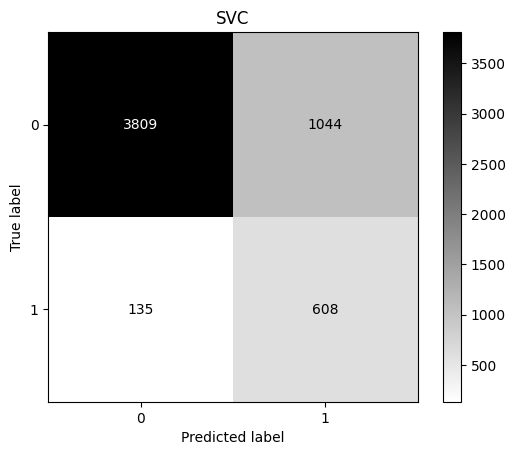

RandomForest - Accuracy: 0.8581129378127234, Precision: 0.48106904231625836, Recall: 0.8721399730820996, F1 Score: 0.6200956937799044
              precision    recall  f1-score   support

           0       0.98      0.86      0.91      4853
           1       0.48      0.87      0.62       743

    accuracy                           0.86      5596
   macro avg       0.73      0.86      0.77      5596
weighted avg       0.91      0.86      0.87      5596



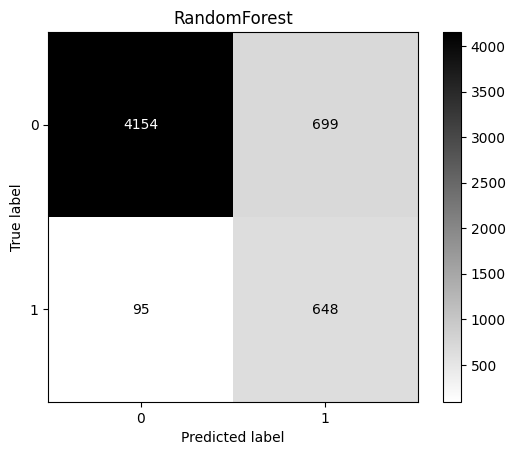

GradientBoosting - Accuracy: 0.6011436740528949, Precision: 0.2197967632668423, Recall: 0.7860026917900403, F1 Score: 0.34352941176470586
              precision    recall  f1-score   support

           0       0.95      0.57      0.71      4853
           1       0.22      0.79      0.34       743

    accuracy                           0.60      5596
   macro avg       0.58      0.68      0.53      5596
weighted avg       0.85      0.60      0.66      5596



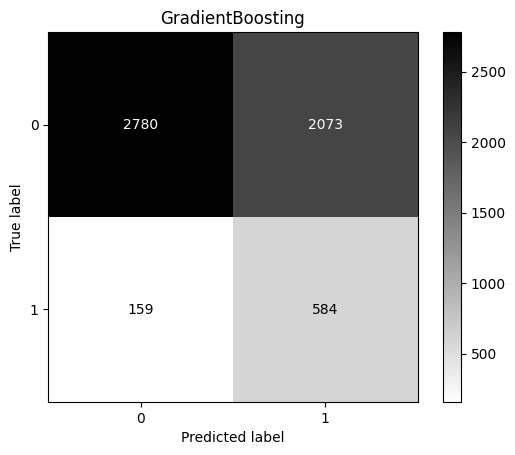

/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_logistic.py:460: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression - Accuracy: 0.6890636168691923, Precision: 0.26651053864168617, Recall: 0.765814266487214, F1 Score: 0.3954134815844336
              precision    recall  f1-score   support

           0       0.95      0.68      0.79      4853
           1       0.27      0.77      0.40       743

    accuracy                           0.69      5596
   macro avg       0.61      0.72      0.59      5596
weighted avg       0.86      0.69      0.74      5596



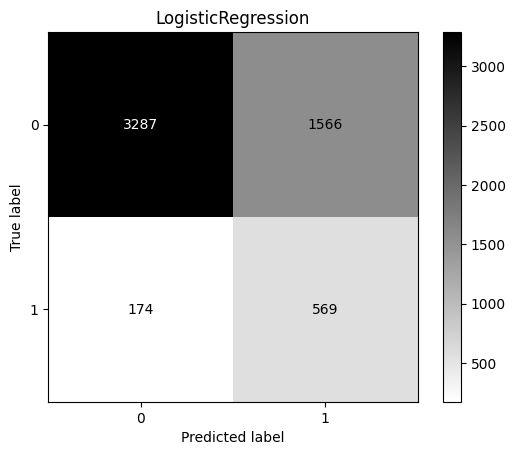

                Model  Accuracy  Precision    Recall  F1 Score  \
0                 SVC  0.789314   0.368039  0.818304  0.507724   
1        RandomForest  0.858113   0.481069  0.872140  0.620096   
2    GradientBoosting  0.601144   0.219797  0.786003  0.343529   
3  LogisticRegression  0.689064   0.266511  0.765814  0.395413   

   False Negatives  
0              135  
1               95  
2              159  
3              174  

Falsos Negativos para SVC:
['DUTRA', 'NASCIMENTO', 'COELHO', 'VOGADO', 'GUERREIRO', 'BARROSO', 'PENTEADO', 'ESTEVO', 'BRAS', 'CARDOSO', 'TORRES', 'ZHAMMYRARAUJO', 'FERREIRA', 'CORDEIRO', 'LOPES', 'CAMPOS', 'CUNHA', 'BARRA', 'ESPIRITO', 'NOBRE', 'TOURINHO', 'FERRAZ', 'BENTES', 'SOARES', 'AZEVEDO', 'BEZERROS', 'PANTOJA', 'ERAO', 'TAVARES', 'DAMASCENO', 'BARROS', 'FREIRE', 'VAVA', 'PASSOS', 'CARMO', 'CAVALCANTE', 'PIMENTEL', 'CAMARGO', 'COSTA', 'FRAGOSO', 'FREITAS', 'ROBISPIERRE', 'KYRIACOPOULOS', 'COUTINHO', 'CASTRO', 'ARRUDA', 'MORAIS', 'VIEIRA', 'SOCORRO', 

In [ ]:
# Treinar os modelos
classifiers = {
    'SVC': SVC(),
    'RandomForest': RandomForestClassifier(),
    'GradientBoosting': GradientBoostingClassifier(),
    'LogisticRegression': LogisticRegression()
}

# Dicionário para armazenar as métricas
metrics = {
    'Model': [],
    'Accuracy': [],
    'Precision': [],
    'Recall': [],
    'F1 Score': [],
    'False Negatives': []
}

# Dicionário para armazenar os falsos negativos
false_negatives = {}

for model_name, classifier in classifiers.items():
    classifier.fit(X_train_vector, y_train)
    y_pred = classifier.predict(X_unique_words_vector)

    # Calcular as métricas
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)

    # Calcular a matriz de confusão
    cm = confusion_matrix(y_true, y_pred)
    fn = cm[1, 0]  # Falsos Negativos

    # Adicionar as métricas ao dicionário
    metrics['Model'].append(model_name)
    metrics['Accuracy'].append(accuracy)
    metrics['Precision'].append(precision)
    metrics['Recall'].append(recall)
    metrics['F1 Score'].append(f1)
    metrics['False Negatives'].append(fn)

    # Encontrar os falsos negativos
    fn_indices = [i for i, (true, pred) in enumerate(zip(y_true, y_pred)) if true == 1 and pred == 0]
    false_negatives[model_name] = unique_words_df.iloc[fn_indices]['palavra'].tolist()

    # Imprimir o relatório de classificação
    report = classification_report(y_true, y_pred)
    print(f"{model_name} - Accuracy: {accuracy}, Precision: {precision}, Recall: {recall}, F1 Score: {f1}")
    print(report)

    # Gerar a matriz de confusão
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
    disp.plot(cmap='binary')
    plt.title(model_name)
    plt.show()

# Criar o dataframe com as métricas
metrics_df = pd.DataFrame(metrics)
print(metrics_df)

# Exibir os falsos negativos para cada modelo
for model_name, fn_list in false_negatives.items():
    print(f"\nFalsos Negativos para {model_name}:")
    print(fn_list)